# 02. Sequential Multi-Agent 구현
**학습 목표:** Research Subgraph의 도구 사용, Agent 간 State 전달, 순차 실행, 출처 점검을 구현한다.  
`.env`의 `OPENAI_API_KEY`로 실제 LLM을 호출하고 `TAVILY_API_KEY`로 실시간 웹 검색을 호출하므로 실행마다 비용이 발생하며, 결과가 실행 시점의 웹 자료에 따라 달라질 수 있다.

## 1. 핵심 개념과 전체 아키텍처
상위 Graph는 **Research → Technology → Writer → Review** 순서를 고정한다.  
Research Agent 안에서는 **범위 결정 → 웹 검색**이 실행된다.  
상위 순서와 내부 판단을 구분해 읽는다.

```mermaid
flowchart LR
  A[START] --> R[Research Subgraph]
  R --> T[Technology Analyst]
  T --> W[Report Writer]
  W --> V[Review Agent]
  V --> Z[END]
```

## 2. Import와 LLM 설정
`common.ai_model.get_llm_model()`은 `.env`의 `MODEL_BASE_URL`과 `MODEL_ID` 값으로 `ChatOpenAI`를 초기화한다.   
모델명은 `.env`의 `MODEL_ID` 값을 따르며, 값이 없으면 `furiosa-ai/Qwen3-8B-FP8`을 기본값으로 사용한다.

In [1]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

from typing import TypedDict

from common.ai_model import get_llm_model

# 02·03번과 동일한 방식으로 클라이언트만 준비한다. 이 설계 노트에서는 invoke를 호출하지 않는다.
llm_model = get_llm_model()
print(llm_model.model_name)

furiosa-ai/Qwen3-8B-FP8


In [ ]:
import re

def strip_think(text: str) -> str:
    """Qwen3 등 추론 모델이 답변 앞에 내놓는 <think>...</think> 사고 과정(주로 영어)을 제거하고 최종 답변만 남긴다."""
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()

## 3. Tavily 웹 검색 도구
`TAVILY_API_KEY`로 `TavilyClient`를 초기화해 범주별 질의로 실제 웹 검색을 수행한다.  
매 실행마다 최신 웹 자료를 가져오므로 결과(제목·URL·요지)가 실행 시점에 따라 달라질 수 있다.

In [3]:
from tavily import TavilyClient

from common.config import TAVILY_API_KEY

tavily_client = TavilyClient(api_key=TAVILY_API_KEY)

# print(TAVILY_API_KEY)

In [4]:
# 범주별 검색 질의: Research Agent가 고른 범주를 실제 웹 검색 질의로 변환한다.
CATEGORY_QUERIES = {
    "technology": "2026 AI 기술 동향 성능 벤치마크",
    "industry": "2026 AI 산업 도입 현황 기업 활용률",
    "governance": "AI 위험관리 프레임워크 거버넌스 규제",
}


def search_sources(categories: list[str]) -> list[dict]:
    """Research Agent가 선택한 범주에 대해 Tavily로 실제 웹 검색을 수행한다."""
    cards = []
    for category in categories:
        query = CATEGORY_QUERIES.get(category)
        if not query:
            continue
        response = tavily_client.search(query=query, max_results=2, search_depth="basic")
        for result in response.get("results", []):
            cards.append({
                "id": f"S{len(cards) + 1}",
                "category": category,
                "title": result.get("title", ""),
                "url": result.get("url", ""),
                # 요지는 검색 결과 본문 일부를 그대로 담는다(새로운 수치·사실을 만들지 않는다).
                "evidence": (result.get("content") or "")[:300],
            })
    return cards


def format_sources(cards: list[dict]) -> str:
    """LLM이 출처 ID와 근거를 함께 읽도록 간결하게 정리한다."""
    # 모델이 각 주장에 [S번호]를 그대로 인용할 수 있도록 ID를 맨 앞에 노출한다.
    return "\n".join(
        f'[{card["id"]}] {card["title"]}: {card["evidence"]} ({card["url"]})'
        for card in cards
    )

## 4. State 정의
`ReportState`는 상위 Agent 간 공유 계약이다.  
`ResearchState`는 Research Subgraph의 내부 계획을 추가로 보관한다.


In [5]:
class ReportState(TypedDict, total=False):
        user_request: str
        research_results: list[dict]
        technology_analysis: str
        final_report: str
        review_notes: str


## 5. Research Agent Subgraph
`StateGraph(ResearchState)`는 Agent의 내부 단계다.  
컴파일된 Graph를 상위 Graph의 Node로 넣으면 공통 Key인 `user_request`, `research_results`가 전달된다.

In [6]:
class ResearchState(TypedDict, total=False):
    user_request: str
    research_scope: list[str]
    research_results: list[dict]


def decide_research_scope(state: ResearchState) -> dict:
    """요청을 보고 자료 조회 범위를 정한다."""
    # 판단 단계: 어떤 카테고리를 조회할지는 요청 내용에 따라 달라진다.
    scope = ["technology", "governance"]
    if "산업" in state["user_request"]:
        scope.append("industry")
    return {"research_scope": scope}


def retrieve_research(state: ResearchState) -> dict:
    """결정된 범위를 도구에 전달해 Tavily 웹 검색 결과를 가져온다."""
    # 실행 단계: 앞서 정한 범위로 웹 검색 도구를 그대로 호출한다(추가 판단 없음).
    return {"research_results": search_sources(state["research_scope"])}


# Research Agent 내부의 판단(decide_scope) → 도구 사용(web_search)을 별도 Subgraph로 표현한다.
research_builder = StateGraph(ResearchState)
research_builder.add_node("decide_scope", decide_research_scope)
research_builder.add_node("web_search", retrieve_research)
research_builder.add_edge(START, "decide_scope")
research_builder.add_edge("decide_scope", "web_search")
research_builder.add_edge("web_search", END)
# 컴파일된 Subgraph를 상위 Graph에는 하나의 Node처럼 등록한다.
research_agent = research_builder.compile()

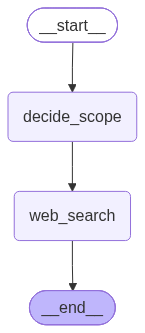

In [7]:
research_agent

## 6. Technology Analyst와 Report Writer
각 Agent는 입력 자료를 읽고 자신의 출력 Key만 반환한다.  
Writer는 근거 카드의 ID를 인용하도록 지시받는다.


In [8]:
def technology_agent(state: ReportState) -> dict:
        """Research 결과를 기술 분석으로 바꾼다."""
        prompt = (
            "당신은 AI 기술 분석가다. 제공 자료에서 확인되는 기술 동향과 한계를 "
            "2~3문장으로 설명하고 각 주장에 [S번호]를 붙여라. 자료 밖의 사실은 쓰지 마라.\n"
            f"요청: {state['user_request']}\n자료:\n{format_sources(state['research_results'])}"
        )
        return {"technology_analysis": strip_think(llm_model.invoke(prompt).content)}


def report_writer(state: ReportState) -> dict:
        """기술 분석을 Markdown 보고서로 정리한다."""
        prompt = (
            "당신은 보고서 작성자다. 제목, 핵심 분석, 한계, 참고자료를 포함한 짧은 "
            "Markdown 보고서를 작성하라. 작성결과는 한글로 작성해라. 주장 뒤에 [S번호]를 붙이고 자료 밖의 수치나 "
            "사례를 만들지 마라.\n"
            f"요청: {state['user_request']}\n분석: {state['technology_analysis']}\n"
            f"자료:\n{format_sources(state['research_results'])}"
        )
        return {"final_report": strip_think(llm_model.invoke(prompt).content)}


## 7. Review Agent
인용 ID의 존재는 코드로 확인한다.  
LLM은 제공된 자료와 주장 사이의 차이를 점검하지만, 최종 사실 확인은 원문 대조가 필요하다.


In [9]:
def review_agent(state: ReportState) -> dict:
    """인용 ID를 기계적으로 검사하고 주장·근거 대조 의견을 구한다."""
    # 1) 코드로 하는 기계적 검사: 보고서의 [S번호]가 실제 자료 카드에 존재하는지만 확인한다.
    known_ids = {card["id"] for card in state["research_results"]}
    # known_ids만 순회해 포함 여부를 보면 보고서에만 있는 미등록(환각) 인용은 애초에 찾을 수 없으므로,
    # 보고서 텍스트에서 [S번호] 형태를 전부 추출한 뒤 known_ids와 차집합을 구해 미등록 ID를 가려낸다.
    cited_ids = set(re.findall(r"\[(S\d+)\]", state["final_report"]))
    unknown_ids = cited_ids - known_ids
    citation_check = (
        f"인용 ID {len(cited_ids)}개, 미등록 ID: {sorted(unknown_ids)}"
        if cited_ids else "인용 ID 없음: 출처 표기가 필요하다."
    )
    # 2) LLM이 하는 의미 판단: 주장이 자료 내용과 실제로 들어맞는지는 모델에 맡긴다.
    prompt = (
        "당신은 보고서 검토자다. 자료 카드와 보고서 주장을 비교해 "
        "'근거로 설명 가능', '자료로 판단 불가', '추가 확인 필요'로 구분하라. "
        "카드에 없는 수치·인과관계·일반화는 지적하라.\n"
        f"자료:\n{format_sources(state['research_results'])}\n"
        f"보고서:\n{state['final_report']}"
    )
    judgment = strip_think(llm_model.invoke(prompt).content)
    return {"review_notes": (
        f"{citation_check}\n\n{judgment}\n\n"
        "주의: 인용 ID 검사는 출처 존재만 확인한다. 주장과 원문의 일치는 사람이 최종 대조해야 한다."
    )}


## 8. 상위 Graph 구성과 Compile
`add_node`는 전문 Agent를 등록하고 `add_edge`는 순서를 정의한다.  
Research는 컴파일된 Subgraph이며 다른 세 Agent는 역할별 Node다.


In [10]:
builder = StateGraph(ReportState)
builder.add_node("research_agent", research_agent)
builder.add_node("technology_agent", technology_agent)
builder.add_node("report_writer", report_writer)
builder.add_node("review_agent", review_agent)

# 모든 Edge가 1:1로 이어지므로 네 Agent는 고정된 순서로만 실행된다(Sequential).
builder.add_edge(START, "research_agent")
builder.add_edge("research_agent", "technology_agent")
builder.add_edge("technology_agent", "report_writer")
builder.add_edge("report_writer", "review_agent")
builder.add_edge("review_agent", END)
graph = builder.compile()


## 9. Graph 시각화
PNG 생성이 실패하면 Mermaid 코드가 출력된다.  
시각화 실패가 실습 실행을 막지 않는다.


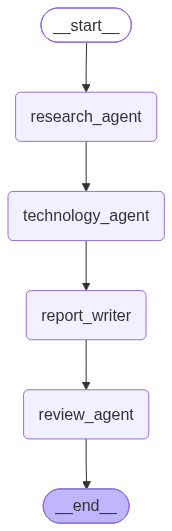

In [11]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    # 시각화 서비스가 없어도 Graph의 실행은 계속된다.
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())


In [12]:
initial_state = {"user_request": "2026년 10월 21일 기준 최근 1주일 동안의 AI 기술 동향과 위험 관리 관점을 분석한 보고서를 한국어로 작성하라."}
final_state = dict(initial_state)

graph.invoke(initial_state)

{'user_request': '2026년 10월 21일 기준 최근 1주일 동안의 AI 기술 동향과 위험 관리 관점을 분석한 보고서를 한국어로 작성하라.',
 'research_results': [{'id': 'S1',
   'category': 'technology',
   'title': '한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및...',
   'url': 'https://www.facebook.com/ITKOREANIA/posts/-the-ai-report-2026-1-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B-%ED%98%84%ED%99%A9-%EB%B6%84%EC%84%9D-%EB%B0%8F-%EC%A0%95%EB%B6%80-%EC%A3%BC%EB%8F%84%EC%9D%98-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%A7%88%EB%A0%A8-%ED%95%84%EC%9A%94%EC%84%B1-ai-%EC%84%B1%EB%8A%A5-%EB%AC%B4%EC%97%87%EC%9C%BC%EB%A1%9C-%EC%96%B4%EB%96%BB%EA%B2%8C-%ED%8F%89%EA%B0%80%ED%95%B4%EC%95%BC-%ED%95%A0/1224540443199953',
   'evidence': "## 한국지능정보사회진흥원's post\n\n### 한국지능정보사회진흥원\n\n28 January  ·\n\n📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및 정부 주도의 벤치마크 마련 필요성\n\n🤖📊 “AI 성능, 무엇으로 어떻게 평가해야 할까?”\n\n대규모 언어모델(LLM) 확산과 함께\n\nAI 모델 간 경쟁은 더욱 치열해지고 있지만,\n\n그 성능을 공정하고 신뢰성 있게 비교·검증할 수 있는 기준의 중요성도\n\n빠르게 커지고 있습니다.\n\n이번 리포

## 10. 실행과 State 변화 확인
`stream(..., stream_mode="updates")`는 각 Node가 반환한 **부분 업데이트**를 보여 준다.  
매 실행마다 네 Agent가 모두 LLM을 호출하므로 API 비용이 발생한다.


In [13]:
initial_state = {"user_request": "2026년 10월 21일 최근 기준 1주일 동안의 AI 기술 동향과 위험 관리 관점을 분석한 보고서를 한국어로 작성하라."}
final_state = dict(initial_state)

# stream(..., stream_mode="updates")는 각 Node가 반환한 변경분만 보여 주므로,
# 어떤 Agent가 State의 어떤 Key를 채웠는지 실행 순서대로 확인할 수 있다.
for update in graph.stream(initial_state, stream_mode="updates"):
    node_name, changed_values = next(iter(update.items()))
    final_state.update(changed_values)
    print(f"{node_name}: {list(changed_values)}")


# test: 최종 State에 모든 Key가 채워졌는지 확인한다.
assert final_state["research_results"]
assert final_state["technology_analysis"]
assert final_state["final_report"]
assert final_state["review_notes"]

research_agent: ['user_request', 'research_results']
technology_agent: ['technology_analysis']
report_writer: ['final_report']
review_agent: ['review_notes']


In [14]:
final_state

{'user_request': '2026년 10월 21일 최근 기준 1주일 동안의 AI 기술 동향과 위험 관리 관점을 분석한 보고서를 한국어로 작성하라.',
 'research_results': [{'id': 'S1',
   'category': 'technology',
   'title': '한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및...',
   'url': 'https://www.facebook.com/ITKOREANIA/posts/-the-ai-report-2026-1-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B-%ED%98%84%ED%99%A9-%EB%B6%84%EC%84%9D-%EB%B0%8F-%EC%A0%95%EB%B6%80-%EC%A3%BC%EB%8F%84%EC%9D%98-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%A7%88%EB%A0%A8-%ED%95%84%EC%9A%94%EC%84%B1-ai-%EC%84%B1%EB%8A%A5-%EB%AC%B4%EC%97%87%EC%9C%BC%EB%A1%9C-%EC%96%B4%EB%96%BB%EA%B2%8C-%ED%8F%89%EA%B0%80%ED%95%B4%EC%95%BC-%ED%95%A0/1224540443199953',
   'evidence': "## 한국지능정보사회진흥원's post\n\n### 한국지능정보사회진흥원\n\n28 January  ·\n\n📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및 정부 주도의 벤치마크 마련 필요성\n\n🤖📊 “AI 성능, 무엇으로 어떻게 평가해야 할까?”\n\n대규모 언어모델(LLM) 확산과 함께\n\nAI 모델 간 경쟁은 더욱 치열해지고 있지만,\n\n그 성능을 공정하고 신뢰성 있게 비교·검증할 수 있는 기준의 중요성도\n\n빠르게 커지고 있습니다.\n\n이번 리포

## 11. 최종 결과
보고서와 검토 의견을 따로 제시한다.  
출처 URL은 Tavily가 반환한 웹 검색 결과에서 확인한다.

In [15]:
from IPython.display import Markdown, display

display(Markdown(final_state["final_report"]))
display(Markdown("### 검토 의견\n" + final_state["review_notes"]))
print("자료 출처:")
for card in final_state["research_results"]:
    print(f"[{card['id']}] {card['title']} — {card['url']}")


```markdown
# 2026년 10월 21일 기준 1주일 동안의 AI 기술 동향 및 위험 관리 분석 보고서

## 제목
AI 기술 동향과 위험 관리의 최근 동향 분석

## 핵심 분석

1. **벤치마크 데이터셋의 중요성 증가**  
   2026년 10월 21일 기준 1주일 동안 AI 기술 동향에서 가장 두드러진 흐름은 벤치마크 데이터셋의 중요성 증가입니다. 대규모 언어모델(LLM)의 확산으로 AI 모델 간 경쟁이 치열해지면서, 공정하고 신뢰성 있는 성능 비교·검증을 위한 기준이 점점 더 필요해지고 있습니다. 이에 따라 정부 주도의 공공 벤치마크 마련 필요성에 대한 논의가 활발해지고 있습니다 [S1].

2. **AI 위험 관리의 인식 확산**  
   AI 위험 관리와 관련하여, 기업이 GRC(Governance, Risk, and Compliance) 프레임워크를 통해 윤리적, 법적, 규제적 위험을 관리해야 한다는 인식이 확산되고 있습니다. 이는 AI 기술의 책임 있는 활용을 위한 필수적인 접근법으로 자리 잡고 있으며, 기업 내부에서 위험 관리 체계 구축에 대한 관심이 높아지고 있습니다 [S3].

## 한계

- **데이터셋의 공정성과 편향성 문제**  
  벤치마크 데이터셋의 공정성과 편향성 문제는 여전히 해결되지 않은 과제로 남아 있으며, 이는 AI 모델의 성능 평가에 영향을 미칠 수 있는 요소입니다.

- **GRC 프레임워크의 구현 난이도**  
  GRC 프레임워크의 구현은 기업 내부 조직 구조와 문화에 따라 차이가 크며, 모든 기업이 쉽게 도입할 수 있는 수준이 아닙니다.

## 참고자료

- [S1] 한국지능정보사회진흥원 - [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및 정부 주도의 벤치마크 마련 필요성  
- [S3] AI 위험 관리 프레임워크: 거버넌스, 리스크, 규정 준수 | 인사이트리포트 | 삼성SDS
```

### 검토 의견
인용 ID 2개, 미등록 ID: []

다음은 보고서의 각 주장과 자료 카드(S1~S4)를 비교하여 **'근거로 설명 가능', '자료로 판단 불가', '추가 확인 필요'**로 구분한 결과입니다. 또한, **자료에 없는 수치, 인과관계, 일반화** 등을 지적합니다.

---

## 🔍 1. **벤치마크 데이터셋의 중요성 증가**

### 보고서 주장:
> 2026년 10월 21일 기준 1주일 동안 AI 기술 동향에서 가장 두드러진 흐름은 벤치마크 데이터셋의 중요성 증가입니다. 대규모 언어모델(LLM)의 확산으로 AI 모델 간 경쟁이 치열해지면서, 공정하고 신뢰성 있는 성능 비교·검증을 위한 기준이 점점 더 필요해지고 있습니다. 이에 따라 정부 주도의 공공 벤치마크 마련 필요성에 대한 논의가 활발해지고 있습니다 [S1].

### 자료 카드 비교:
- **S1**은 "AI 성능, 무엇으로 어떻게 평가해야 할까?"라는 질문을 제기하며, **LLM 확산과 AI 모델 간 경쟁의 증가**를 언급하고, **공정하고 신뢰성 있는 비교·검증 기준의 필요성**을 강조합니다. 또한, **정부 주도의 공공 벤치마크 마련 필요성**에 대한 논의가 활발하다고 언급합니다.
- **S2**는 S1과 동일한 내용을 반복적으로 언급하며, 동일한 근거를 제공합니다.

### 분류:
✅ **근거로 설명 가능**  
- 보고서의 주장은 S1과 S2에서 제공된 내용과 일치합니다.  
- **LLM 확산 → 경쟁 치열 → 공정한 기준 필요 → 정부 주도의 벤치마크 필요성**이라는 논리적 흐름이 자료에 명시되어 있습니다.

### 지적 사항:
- **수치**: 보고서에서 "2026년 10월 21일 기준 1주일 동안"이라는 시간 범위를 사용하지만, 자료(S1, S2)에서는 구체적인 시간 범위나 데이터셋의 변화량에 대한 수치가 제공되지 않아 **추가 확인 필요**입니다.
- **일반화**: "1주일 동안의 AI 기술 동향에서 가장 두드러진 흐름"이라는 표현은 자료에 명시된 내용을 일반화한 것으로, **추가 확인 필요**입니다.

---

## 🔍 2. **AI 위험 관리의 인식 확산**

### 보고서 주장:
> AI 위험 관리와 관련하여, 기업이 GRC(Governance, Risk, and Compliance) 프레임워크를 통해 윤리적, 법적, 규제적 위험을 관리해야 한다는 인식이 확산되고 있습니다. 이는 AI 기술의 책임 있는 활용을 위한 필수적인 접근법으로 자리 잡고 있으며, 기업 내부에서 위험 관리 체계 구축에 대한 관심이 높아지고 있습니다 [S3].

### 자료 카드 비교:
- **S3**는 AI 위험 관리에 대한 GRC 프레임워크의 필요성을 언급하며, **기업이 GRC 프레임워크를 통해 위험을 관리해야 한다는 인식**이 확산되고 있다고 설명합니다. 또한, **레노버와 IDC의 설문조사**를 인용하여 **2,920명의 IT 및 비즈니스 의사결정권자**가 이에 대한 인식을 가지고 있다고 언급합니다.

### 분류:
✅ **근거로 설명 가능**  
- 보고서의 주장은 S3에서 제공된 내용과 일치합니다.  
- **GRC 프레임워크의 필요성**과 **기업 내부에서 위험 관리 체계 구축에 대한 관심 증가**는 S3에서 명시된 내용입니다.

### 지적 사항:
- **수치**: 보고서는 "2,920명의 IT 및 비즈니스 의사결정권자"라는 수치를 사용하지만, 자료(S3)에서는 "2,920명"이라는 수치가 명시되어 있으므로 **근거로 설명 가능**입니다.
- **일반화**: "인식이 확산되고 있다"는 표현은 S3에서 제공된 설문조사 결과를 바탕으로 한 일반화이므로 **근거로 설명 가능**입니다.

---

## 🔍 3. **한계: 데이터셋의 공정성과 편향성 문제**

### 보고서 주장:
> 벤치마크 데이터셋의 공정성과 편향성 문제는 여전히 해결되지 않은 과제로 남아 있으며, 이는 AI 모델의 성능 평가에 영향을 미칠 수 있는 요소입니다.

### 자료 카드 비교:
- **S1, S2**에서는 벤치마크 데이터셋의 중요성과 정부 주도의 벤치마크 마련 필요성에 대해 언급하지만, **공정성과 편향성 문제**에 대한 구체적인 내용은 제공되지 않습니다.
- **S3, S4**는 AI 위험 관리와 관련된 내용을 다루고 있지만, 데이터셋의 공정성과 편향성 문제에 대한 구체적인 언급은 없습니다.

### 분류:
⚠️ **추가 확인 필요**  
- 보고서에서 제기된 **데이터셋의 공정성과 편향성 문제**는 자료(S1~S4)에서 명시적으로 언급되지 않았습니다.  
- 이는 **추가 자료 또는 연구**가 필요합니다.

---

## 🔍 4. **한계: GRC 프레임워크의 구현 난이도**

### 보고서 주장:
> GRC 프레임워크의 구현은 기업 내부 조직 구조와 문화에 따라 차이가 크며, 모든 기업이 쉽게 도입할 수 있는 수준이 아닙니다.

### 자료 카드 비교:
- **S3**는 GRC 프레임워크의 필요성을 강조하며, **구현 난이도**에 대한 언급은 없습니다.
- **S4**는 AI 규제 프레임워크의 구성 요소를 설명하지만, 구체적인 구현 난이도나 기업 차원의 차이에 대한 언급은 없습니다.

### 분류:
⚠️ **추가 확인 필요**  
- 보고서에서 제기된 **GRC 프레임워크의 구현 난이도**는 자료(S1~S4)에서 명시적으로 언급되지 않았습니다.  
- 이는 **추가 자료 또는 연구**가 필요합니다.

---

## ✅ 최종 분류 요약

| 보고서 주장 | 분류 | 근거 자료 | 지적 사항 |
|-------------|------|-----------|-----------|
| 벤치마크 데이터셋의 중요성 증가 | 근거로 설명 가능 | S1, S2 | 수치와 일반화에 대한 추가 확인 필요 |
| AI 위험 관리의 인식 확산 | 근거로 설명 가능 | S3 | 수치와 일반화에 대한 근거로 설명 가능 |
| 데이터셋의 공정성과 편향성 문제 | 추가 확인 필요 | - | 자료에 없음 |
| GRC 프레임워크의 구현 난이도 | 추가 확인 필요 | - | 자료에 없음 |

---

## ✅ 결론

- 보고서의 **첫 번째 주장**(벤치마크 데이터셋의 중요성 증가)은 **S1, S2**에서 제공된 내용과 일치하며, **근거로 설명 가능**합니다.
- 보고서의 **두 번째 주장**(AI 위험 관리의 인식 확산)은 **S3**에서 제공된 내용과 일치하며, **근거로 설명 가능**합니다.
- **데이터셋의 공정성과 편향성 문제**, **GRC 프레임워크의 구현 난이도**는 자료에 명시되지 않아 **추가 확인 필요**입니다.
- 보고서는 **일반화**와 **수치**에 대한 명확한 근거를 제공하지 않아, **추가 검토**가 필요합니다.

주의: 인용 ID 검사는 출처 존재만 확인한다. 주장과 원문의 일치는 사람이 최종 대조해야 한다.

자료 출처:
[S1] 한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및... — https://www.facebook.com/ITKOREANIA/posts/-the-ai-report-2026-1-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B-%ED%98%84%ED%99%A9-%EB%B6%84%EC%84%9D-%EB%B0%8F-%EC%A0%95%EB%B6%80-%EC%A3%BC%EB%8F%84%EC%9D%98-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%A7%88%EB%A0%A8-%ED%95%84%EC%9A%94%EC%84%B1-ai-%EC%84%B1%EB%8A%A5-%EB%AC%B4%EC%97%87%EC%9C%BC%EB%A1%9C-%EC%96%B4%EB%96%BB%EA%B2%8C-%ED%8F%89%EA%B0%80%ED%95%B4%EC%95%BC-%ED%95%A0/1224540443199953
[S2] Instagram — https://www.instagram.com/p/DUEm-l5iEmt
[S3] AI 위험 관리 프레임워크: 거버넌스, 리스크, 규정 준수 | 인사이트리포트 | 삼성SDS — https://www.samsungsds.com/kr/insights/ai-risk-management-framework.html
[S4] AI 규제 프레임워크 | FlowHunt — https://www.flowhunt.io/ko/%EC%9A%A9%EC%96%B4%EC%A7%91/ai-regulatory-frameworks


## 12. 핵심 개념 정리와 수강생 미션
Research의 판단·도구 사용은 내부 Subgraph에서 일어나고, 상위 Graph는 전문 Agent들의 협업 순서를 관리한다.  
Agent는 맡은 State Key만 반환한다.

**미션:** Review Agent가 개선 사항을 `review_notes`에 2개 이상 제안하도록 프롬프트를 바꾼다.  
인용 ID가 빠진 보고서를 넣어 경고가 출력되는지도 확인한다.
